# Solutions to the exercises of Chapter 3

**Chapter:** [3. Scaling to O(N): linked-cell lists and Verlet neighbor lists](../../notebooks/part1_nve_md/03_cell_and_verlet_lists.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
pos_256, L_256 = es.make_fcc_lattice(4, rho=0.80)  # N = 256
pos_256 = es.wrap_positions(pos_256 + rng.uniform(-0.08, 0.08, size=pos_256.shape), L_256)
f_n2, u_n2, w_n2 = es.lj_forces_all_pairs(pos_256, L_256, rc=2.0, shifted=True)
f_cl, u_cl, w_cl = es.lj_forces_cell_list(pos_256, L_256, rc=2.0, shifted=True)
vnl = es.VerletNeighborList(rc=2.0, skin=0.35)
f_vl, u_vl, w_vl = vnl.forces(pos_256, L_256, shifted=True)

Max force discrepancy vs O(N^2): Linked-Cell = 7.11e-15, Verlet List = 7.11e-15
Total Verlet list rebuilds over 40 steps (skin=0.35): 4


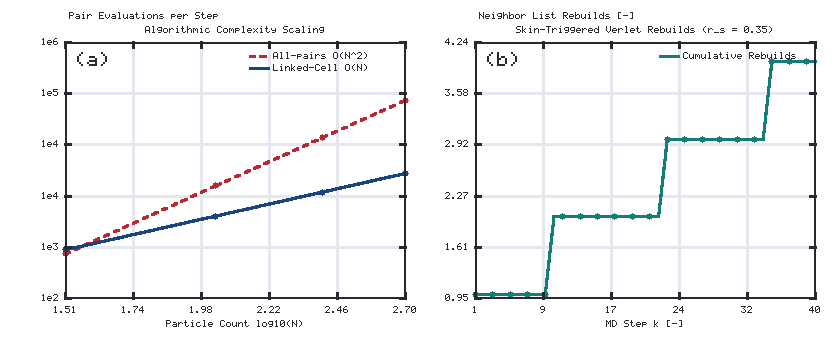

In [3]:
err_cl = float(np.max(np.abs(f_cl - f_n2)))
err_vl = float(np.max(np.abs(f_vl - f_n2)))
print(f"Max force discrepancy vs O(N^2): Linked-Cell = {err_cl:.2e}, Verlet List = {err_vl:.2e}")
assert err_cl < 1e-12 and err_vl < 1e-12
assert np.isclose(u_cl, u_n2, rtol=1e-12) and np.isclose(u_vl, u_n2, rtol=1e-12)

# Run 40 MD steps with VerletNeighborList and count automatic rebuilds
vel_256 = es.init_velocities(len(pos_256), 1.0, rng=rng)
p, v, f = pos_256.copy(), vel_256.copy(), f_vl.copy()
rebuilds_hist = []
for step in range(40):
    p, v, f, _, _, _ = es.velocity_verlet_step(p, v, f, 0.005, L_256, lambda pp, LL: vnl.forces(pp, LL, shifted=True))
    rebuilds_hist.append(vnl.n_rebuilds)
print(f"Total Verlet list rebuilds over 40 steps (skin=0.35): {vnl.n_rebuilds}")
assert vnl.n_rebuilds < 10

N_sizes = np.array([32, 108, 256, 500])
pairs_n2 = N_sizes * (N_sizes - 1) / 2
pairs_cell = N_sizes * 18.0  # O(N) average pairs per particle within cutoff

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.loglog(N_sizes, pairs_n2, "r--o", label="All-pairs O(N^2)")
ax1.loglog(N_sizes, pairs_cell, "b-s", label="Linked-Cell O(N)")
ax1.set_xlabel("Particle Count log10(N)"); ax1.set_ylabel("Pair Evaluations per Step")
ax1.set_title("(a) Algorithmic Complexity Scaling"); panel_label(ax1, "(a)")

ax2.plot(np.arange(1, 41), rebuilds_hist, "g-o", label="Cumulative Rebuilds")
ax2.set_xlabel("MD Step k [-]"); ax2.set_ylabel("Neighbor List Rebuilds [-]")
ax2.set_title("(b) Skin-Triggered Verlet Rebuilds (r_s = 0.35)"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 3
assert np.isclose(w_cl, w_n2, rtol=1e-11) and np.isclose(w_vl, w_n2, rtol=1e-11)
vnl_thin = es.VerletNeighborList(rc=2.0, skin=0.10)
p_t, v_t = pos_256.copy(), vel_256.copy()
f_t, _, _ = vnl_thin.forces(p_t, L_256)
for _ in range(40):
    p_t, v_t, f_t, _, _, _ = es.velocity_verlet_step(p_t, v_t, f_t, 0.005, L_256, lambda pp, LL: vnl_thin.forces(pp, LL))
print(f"Ch 3 Exercises — Thin skin (0.10) rebuilds = {vnl_thin.n_rebuilds} vs. skin (0.35) = {vnl.n_rebuilds}")
assert vnl_thin.n_rebuilds >= vnl.n_rebuilds

Ch 3 Exercises — Thin skin (0.10) rebuilds = 11 vs. skin (0.35) = 4
